# 1. Black-Scholes and Monte Carlo

Two ways to price the same European option:

* the **Black-Scholes formula**, exact but limited to simple payoffs;
* **Monte Carlo simulation**, approximate but applicable to almost anything.

The goal of this notebook is to check that they agree, and to measure how fast Monte Carlo converges and how much variance-reduction techniques help.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pricer` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricer import VanillaOption, black_scholes, monte_carlo, binomial, finite_difference, exotics
from pricer.greeks import bump_greeks
from pricer.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT

use_style()
pd.options.display.float_format = "{:.4f}".format

# Reference contract used throughout: an at-the-money one-year option.
call = VanillaOption(spot=100, strike=100, maturity=1.0, rate=0.05, vol=0.2, option_type="call")
put = call.with_(option_type="put")

## 1.1 The closed-form price

Under the risk-neutral measure the stock follows $dS = (r-q)S\,dt + \sigma S\,dW$, and

$$C = S_0 e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad d_{1,2} = \frac{\ln(S_0/K) + (r - q \pm \sigma^2/2)T}{\sigma\sqrt{T}}.$$

In [2]:
c, p = black_scholes.price(call), black_scholes.price(put)
print(f"Call: {c:.4f}   Put: {p:.4f}")

# Put-call parity: C - P = S0 - K exp(-rT). It holds in any arbitrage-free model,
# so it is a model-independent check that the implementation is right.
parity_gap = (c - p) - (call.spot - call.strike * np.exp(-call.rate * call.maturity))
print(f"Put-call parity gap: {parity_gap:.2e}")

Call: 10.4506   Put: 5.5735
Put-call parity gap: 0.00e+00


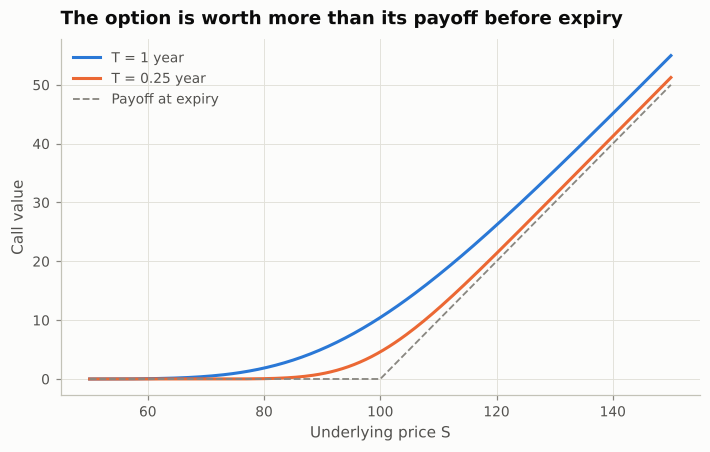

In [3]:
spots = np.linspace(50, 150, 201)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for maturity, color in [(1.0, BLUE), (0.25, ORANGE)]:
    values = [black_scholes.price(call.with_(spot=s, maturity=maturity)) for s in spots]
    ax.plot(spots, values, color=color, label=f"T = {maturity:g} year")
ax.plot(spots, call.payoff(spots), color=MUTED, linestyle="--", linewidth=1.2, label="Payoff at expiry")
ax.set_xlabel("Underlying price S")
ax.set_ylabel("Call value")
ax.set_title("The option is worth more than its payoff before expiry")
ax.legend();

## 1.2 Monte Carlo

The price is a discounted expectation, $C = e^{-rT}\,\mathbb{E}[\max(S_T - K, 0)]$, so it can be estimated by averaging over simulated terminal prices

$$S_T = S_0 \exp\big((r - q - \tfrac{\sigma^2}{2})T + \sigma\sqrt{T}\,Z\big), \qquad Z \sim \mathcal{N}(0,1).$$

The estimate comes with a standard error, which gives a confidence interval.

In [4]:
result = monte_carlo.price(call, n_paths=100_000, seed=1)
low, high = result.confidence_interval(0.95)
print(f"Monte Carlo : {result.price:.4f}  (95% CI: [{low:.4f}, {high:.4f}])")
print(f"Exact       : {black_scholes.price(call):.4f}")

Monte Carlo : 10.3578  (95% CI: [10.2668, 10.4487])
Exact       : 10.4506


### Convergence rate

The error decreases like $1/\sqrt{N}$: one more digit of accuracy costs 100 times more paths. On a log-log plot the standard error is a straight line of slope $-1/2$.

Fitted slope: -0.482 (theory: -0.5)


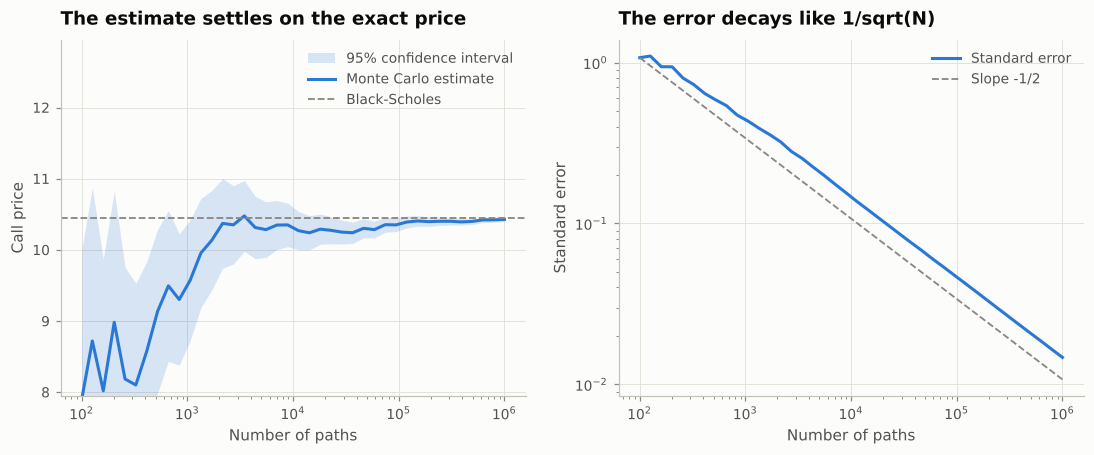

In [5]:
exact = black_scholes.price(call)
n_paths = np.unique(np.logspace(2, 6, 40).astype(int))
results = [monte_carlo.price(call, int(n), seed=1) for n in n_paths]
prices = np.array([r.price for r in results])
errors = np.array([r.std_error for r in results])

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
left.fill_between(n_paths, prices - 1.96 * errors, prices + 1.96 * errors, color=BLUE, alpha=0.18, linewidth=0,
                  label="95% confidence interval")
left.plot(n_paths, prices, color=BLUE, label="Monte Carlo estimate")
left.axhline(exact, color=MUTED, linestyle="--", linewidth=1.2, label="Black-Scholes")
left.set_xscale("log"); left.set_ylim(exact - 2.5, exact + 2.5)
left.set_xlabel("Number of paths"); left.set_ylabel("Call price")
left.set_title("The estimate settles on the exact price"); left.legend()

right.loglog(n_paths, errors, color=BLUE, label="Standard error")
right.loglog(n_paths, errors[0] * np.sqrt(n_paths[0] / n_paths), color=MUTED, linestyle="--", linewidth=1.2,
             label="Slope -1/2")
right.set_xlabel("Number of paths"); right.set_ylabel("Standard error")
right.set_title("The error decays like 1/sqrt(N)"); right.legend();

slope = np.polyfit(np.log(n_paths), np.log(errors), 1)[0]
print(f"Fitted slope: {slope:.3f} (theory: -0.5)")

## 1.3 Variance reduction

Since more paths are expensive, the alternative is to reduce the variance of each sample.

* **Antithetic variates**: use every draw $Z$ together with $-Z$. The two payoffs are negatively correlated, so their average is less noisy.
* **Control variate**: the discounted stock price $e^{-rT}S_T$ is highly correlated with the call payoff and its expectation $S_0e^{-qT}$ is known. Subtracting $\beta\,(e^{-rT}S_T - S_0e^{-qT})$ removes the noise they share without changing the mean.

In [6]:
n = 100_000
settings = {
    "Plain": {},
    "Antithetic": {"antithetic": True},
    "Control variate": {"control_variate": True},
    "Antithetic + control variate": {"antithetic": True, "control_variate": True},
}
rows = []
for name, kwargs in settings.items():
    r = monte_carlo.price(call, n, seed=1, **kwargs)
    rows.append({"Estimator": name, "Price": r.price, "Std error": r.std_error})
table = pd.DataFrame(rows).set_index("Estimator")
# Paths needed for a given accuracy are proportional to the variance.
table["Equivalent speed-up"] = (table["Std error"].iloc[0] / table["Std error"]) ** 2
table

,Price,Std error,Equivalent speed-up
Estimator,,,
Plain,10.3578,0.0464,1.0000
Antithetic,10.4014,0.0328,2.0019
Control variate,10.4275,0.0177,6.8713
Antithetic + control variate,10.4449,0.0088,27.8571


The control variate works better for options that are deep in the money (the payoff is then almost linear in $S_T$) and worse for options far out of the money:

In [7]:
rows = []
for strike in [70, 85, 100, 115, 130]:
    option = call.with_(strike=strike)
    plain = monte_carlo.price(option, n, seed=1).std_error
    controlled = monte_carlo.price(option, n, seed=1, control_variate=True).std_error
    rows.append({"Strike": strike, "Variance divided by": (plain / controlled) ** 2})
pd.DataFrame(rows).set_index("Strike")

,Variance divided by
Strike,
70,426.4231
85,31.6063
100,6.8713
115,2.8101
130,1.6840


## Summary

* The Black-Scholes implementation satisfies put-call parity to machine precision.
* Monte Carlo reproduces the exact price within its confidence interval, with the expected $N^{-1/2}$ error.
* Combining antithetic and control variates gives the same accuracy with far fewer paths.